# SDM374 代理模型综合性能评估报告

**评估对象**：面向 `ramping`（越小越好）的 9 个代理模型
**评估器**：[surrogate_evaluator.py](file:///D:/HuaweiMoveData/Users/11659/Desktop/机器学习项目/Lab6/surrogate_evaluator.py)（Lab6 提供的 `SurrogateEvaluator`）
**数据**：`dataset_same8/train.csv`，2048 条样本，21 维控制权重（3 栋楼 × 7 项指标）

本报告统一评估协议，逐模型输出评估器的四个维度结果，再做横向对比，最后选出 3 个最适合用于参数寻优的代理模型并分析其优劣。

> 说明：本报告只评估“模型是否适合做参数寻优”，不涉及最终真实控制器成绩。conformal 区间包装、线性岭回归等仅作为对照或包装层，不计入主榜；主榜覆盖仓库中已有的 9 个代理模型。

> **结论速览**：按评估器的 4 项检查排序，前 3 名为 **XGBoost（原始 21 维）、HistGradientBoosting、SPMM 半参数混合**。但需要把“排序”与“显著领先”分开看：XGB 与 HistGB 同处第一梯队——XGB 的整体 MAE、Spearman ρ、Top-K 平均真实分位点估计略优，但局部 MAE 仅 6.90 vs 6.92（差 0.2%），局部 RMSE/R² 反而 HistGB 略好；这一差距小于单次折分带来的噪声，不能表述为“明显领先”。第 3 名 SPMM 的入选依赖评估器 1.5× 门槛：它的优势是局部/整体退化最小、响应面平滑、训练最快；门槛移到 1.75×/1.78× 时，RF、CLR 同样会 4/4 通过并可能取代 SPMM（见 6.5）。


In [1]:
# 环境、路径与数据
import sys, time, warnings, contextlib, io, random
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
LAB6_CANDIDATES = [
    Path(r"D:\HuaweiMoveData\Users\11659\Desktop\机器学习项目\Lab6"),
    ROOT.parent / "Lab6",
    ROOT / "Lab6",
]
LAB6 = next((p for p in LAB6_CANDIDATES if (p / "surrogate_evaluator.py").exists()), None)
if LAB6 is None:
    raise FileNotFoundError("找不到 Lab6/surrogate_evaluator.py，请检查路径")
sys.path.insert(0, str(LAB6))
from surrogate_evaluator import SurrogateEvaluator

SEED = 2026
np.random.seed(SEED)
random.seed(SEED)

METRICS = ("cost", "carbon", "peak", "discomfort", "degradation", "ramping", "resilience")
FEATURES = [f"b{b}_{m}" for b in range(1, 4) for m in METRICS]

df = pd.read_csv(ROOT / "dataset_same8" / "train.csv", float_precision="round_trip")
X = df[FEATURES].to_numpy(dtype=float)
y = df["ramping"].to_numpy(dtype=float)

print(f"评估器: {LAB6 / 'surrogate_evaluator.py'}")
print(f"数据: {X.shape[0]} 条样本 × {X.shape[1]} 维特征")
print(f"目标 ramping: min={y.min():.2f}, 中位数={np.median(y):.2f}, max={y.max():.2f}, std={y.std():.2f}")
print(f"最优 5% 阈值（评估器内部使用）: {np.percentile(y, 5):.2f}")

评估器: D:\HuaweiMoveData\Users\11659\Desktop\机器学习项目\Lab6\surrogate_evaluator.py
数据: 2048 条样本 × 21 维特征
目标 ramping: min=115.76, 中位数=161.91, max=242.52, std=15.77
最优 5% 阈值（评估器内部使用）: 132.80


## 1. 统一评估协议

评估器的四个核心维度及通过标准（与 `surrogate_evaluator.py` 源码一致）：

| 维度 | 评估器输出 | 通过标准 |
|---|---|---|
| ① 最优 5% 局部精度 | 阈值、局部样本数、MAE、RMSE、R²、偏差、全样本 MAE | 局部 MAE ≤ 1.5 × 全样本 MAE；偏差 ≥ -3（不允许明显低估好解） |
| ② 排名一致性 | Spearman ρ 及 p 值 | ρ ≥ 0.6 |
| ③ 子集模拟寻优 | 每折 Top-K 平均真实分位、最优真实排名、真实最优值、holdout 最优值、gap | 平均真实分位 ≤ 10%；3 折通过率 ≥ 60% |
| ④ 多模型对比 | `compare_models` 汇总表、综合判定 | 4 项全过 → ✅ 推荐；3 项 → ⚠️ 基本可用；≤2 项 → ❌ 不推荐 |

**本报告的评估层面**：
- 局部精度与排名一致性使用**全量 2048 条样本的 5 折 OOF 预测**。每个样本的预测都来自未见过该样本的折（样本级折外），但超参数是在**同一折分**上选出的，因此存在**选择–评估循环**（selection–evaluation loop），OOF 指标是乐观估计（误差下界 / 性能上界），详见 7.4。
- 相比 8:2 holdout（测试集仅 410 条，最优 5% 只有约 21 条），OOF 下最优区域有 103 条，指标更稳定，也使 9 个模型处于完全相同的评估条件下。
- 子集模拟寻优使用评估器默认的 **3 折 + Top-10**，对所有模型一致。
- 所有模型共用同一个 `KFold(5, shuffle=True, random_state=2026)` 折分和同一 3 折子集折分；折分只做一次，未做重复 CV，因此表中差异不带置信区间。

> **读表提示**：最优 5% 区域（阈值 132.80，n=103）的真实 ramping 只在 115.8–132.8 之间，方差很小；任何向均值收缩的预测都会让**局部 R² 变成大负数**。这是尾部指标的特性，不代表模型整体无用（整体 OOF R² 为 0.60–0.79）。评估器因此把**局部 MAE ≤ 1.5×整体 MAE** 和**偏差方向**作为主要判据，R² 仅作参考。

> **门槛不是定律**：1.5× 是评估器给出的启发式阈值，不是数据决定的常数。第 3 名会随门槛移动而变化，见 6.5 的敏感性分析。


In [2]:
# ---------- 特征表示与模型组件 ----------
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, FunctionTransformer
from scipy.interpolate import BSpline

REF_METRIC = "resilience"


def alr_transform(X):
    # 逐楼 ALR: log(x_i / resilience)，每楼 7 维 -> 6 维，共 18 维
    cols = []
    for b in range(3):
        block = X[:, b * 7:(b + 1) * 7]
        ref = block[:, 6:7]
        for j, m in enumerate(METRICS):
            if m == REF_METRIC:
                continue
            cols.append(np.log(block[:, j:j + 1] / ref))
    return np.hstack(cols)


def clr_transform(X):
    # 逐楼 CLR: log(x_i / g(x))，g 为楼内几何均值，维度不变（21 维，楼内和为 0）
    cols = []
    for b in range(3):
        block = X[:, b * 7:(b + 1) * 7]
        log_b = np.log(block)
        cols.append(log_b - log_b.mean(axis=1, keepdims=True))
    return np.hstack(cols)


def make_poly_ridge(degree, alpha):
    # 多项式特征 + 标准化 + 岭回归，所有步骤只在训练折内拟合
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha, solver="auto")),
    ])


# ---------- 贝叶斯 GAM（P-spline + Gibbs） ----------
def _bspline_basis(x, n_knots=8, degree=3):
    x = np.asarray(x, dtype=float)
    xmin, xmax = float(x.min()), float(x.max())
    if xmax - xmin < 1e-12:
        return np.ones((len(x), 1)), np.array([xmin] * (degree + 1) * 2)
    interior = np.quantile(x, np.linspace(0.0, 1.0, n_knots + 2))[1:-1]
    knots = np.concatenate([np.full(degree + 1, xmin), interior, np.full(degree + 1, xmax)])
    n_basis = len(knots) - degree - 1
    B = np.zeros((len(x), n_basis))
    for i in range(n_basis):
        c = np.zeros(n_basis)
        c[i] = 1.0
        sp = BSpline(knots, c, degree, extrapolate=False)
        B[:, i] = np.nan_to_num(sp(x), nan=0.0)
    return B, knots


def _second_diff_matrix(K):
    if K < 3:
        return np.eye(K)
    D = np.zeros((K - 2, K))
    for i in range(K - 2):
        D[i, i] = 1.0
        D[i, i + 1] = -2.0
        D[i, i + 2] = 1.0
    return D.T @ D + 1e-6 * np.eye(K)


class BayesianGAM(BaseEstimator, RegressorMixin):
    # 贝叶斯 P-spline GAM：B 样条基 + 二阶随机游走光滑先验 + Gibbs 采样
    def __init__(self, n_knots=8, degree=3, n_burn=1000, n_samples=2000, thin=2,
                 a_tau=1.0, b_tau=0.1, a_sigma=1e-3, b_sigma=1e-3, seed=SEED):
        self.n_knots = n_knots
        self.degree = degree
        self.n_burn = n_burn
        self.n_samples = n_samples
        self.thin = thin
        self.a_tau = a_tau
        self.b_tau = b_tau
        self.a_sigma = a_sigma
        self.b_sigma = b_sigma
        self.seed = seed

    def _build_design(self, X, fit=False):
        X = np.asarray(X, dtype=float)
        blocks = []
        if fit:
            self._meta = []
        for j in range(X.shape[1]):
            B, knots = _bspline_basis(X[:, j], self.n_knots, self.degree)
            if fit:
                col_mean = B.mean(axis=0)
                self._meta.append((knots, col_mean))
            else:
                knots, col_mean = self._meta[j]
                n_basis = len(knots) - self.degree - 1
                B = np.zeros((len(X), n_basis))
                for i in range(n_basis):
                    c = np.zeros(n_basis)
                    c[i] = 1.0
                    sp = BSpline(knots, c, self.degree, extrapolate=False)
                    B[:, i] = np.nan_to_num(sp(X[:, j]), nan=0.0)
            blocks.append(B - col_mean)
        return np.hstack([np.ones((X.shape[0], 1)), *blocks])

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n = len(y)

        Z = self._build_design(X, fit=True)
        p = Z.shape[1]
        J = X.shape[1]

        self._slices = []
        col = 1
        for j in range(J):
            knots, _ = self._meta[j]
            Kj = len(knots) - self.degree - 1
            self._slices.append(slice(col, col + Kj))
            col += Kj
        assert col == p

        ZtZ = Z.T @ Z
        Zty = Z.T @ y
        Kpens = [_second_diff_matrix(s.stop - s.start) for s in self._slices]

        sigma2 = float(np.var(y))
        tau = np.ones(J)
        beta = np.linalg.solve(ZtZ + 1e-3 * np.eye(p), Zty)

        n_total = self.n_burn + self.n_samples * self.thin
        beta_keep = np.zeros((self.n_samples, p))
        sigma2_keep = np.zeros(self.n_samples)
        tau_keep = np.zeros((self.n_samples, J))
        kept = 0

        for it in range(n_total):
            P = np.zeros((p, p))
            for j in range(J):
                s = self._slices[j]
                P[s, s] = tau[j] * Kpens[j]
            prec = ZtZ / sigma2 + P
            L = np.linalg.cholesky(prec)
            m = np.linalg.solve(L.T, np.linalg.solve(L, Zty / sigma2))
            beta = m + np.linalg.solve(L.T, rng.standard_normal(p))

            for j in range(J):
                s = self._slices[j]
                bj = beta[s]
                quad = float(bj @ Kpens[j] @ bj)
                shape = self.a_tau + 0.5 * (s.stop - s.start)
                rate = self.b_tau + 0.5 * quad
                tau[j] = rng.gamma(shape, 1.0 / rate)

            resid = y - Z @ beta
            rss = float(resid @ resid)
            shape = self.a_sigma + 0.5 * n
            rate = self.b_sigma + 0.5 * rss
            sigma2 = 1.0 / rng.gamma(shape, 1.0 / rate)

            if it >= self.n_burn and (it - self.n_burn) % self.thin == 0:
                beta_keep[kept] = beta
                sigma2_keep[kept] = sigma2
                tau_keep[kept] = tau
                kept += 1

        self.beta_samples_ = beta_keep
        self.sigma2_samples_ = sigma2_keep
        self.tau_samples_ = tau_keep
        self.beta_mean_ = beta_keep.mean(axis=0)
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return self._build_design(X, fit=False) @ self.beta_mean_


GAM_PARAMS = dict(n_knots=8, degree=3, n_burn=1000, n_samples=2000, thin=2,
                  a_tau=1.0, b_tau=0.1, a_sigma=1e-3, b_sigma=1e-3)


def make_gam(seed=SEED):
    return BayesianGAM(seed=seed, **GAM_PARAMS)

In [3]:
# ---------- BART 与 SPMM ----------
from bartpy2.sklearnmodel import SklearnModel
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

BART_PARAMS = dict(n_trees=50, alpha=0.95, beta=2.0, n_burn=500, n_samples=1000,
                   thin=0.05, n_chains=1, n_jobs=1, store_in_sample_predictions=False)


class SeededBART:
    # 给 bartpy2 套固定种子的 sklearn 风格接口
    def __init__(self, seed=SEED, **params):
        self.seed = seed
        self.params = params
        self.model = None

    def fit(self, X, y):
        np.random.seed(self.seed)
        random.seed(self.seed)
        self.model = SklearnModel(**self.params)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            self.model.fit(np.asarray(X, dtype=float), np.asarray(y, dtype=float))
        return self

    def predict(self, X):
        return self.model.predict(np.asarray(X, dtype=float))


def make_bart(seed=SEED):
    return SeededBART(seed=seed, **BART_PARAMS)


class SemiparametricMixedModel(BaseEstimator, RegressorMixin):
    # 参数项（二次岭回归）+ 非参数项（RBF 核岭回归残差修正）
    def __init__(self, alpha_linear=100.0, alpha_kernel=1.0, gamma=0.05, degree=2):
        self.alpha_linear = alpha_linear
        self.alpha_kernel = alpha_kernel
        self.gamma = gamma
        self.degree = degree

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.scaler_ = StandardScaler().fit(X)
        Z = self.scaler_.transform(X)
        self.poly_ = PolynomialFeatures(self.degree, include_bias=False).fit(Z)
        P = self.poly_.transform(Z)
        self.linear_ = Ridge(alpha=self.alpha_linear).fit(P, y)
        residual = y - self.linear_.predict(P)
        self.kernel_ = KernelRidge(kernel="rbf", alpha=self.alpha_kernel, gamma=self.gamma).fit(Z, residual)
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        Z = self.scaler_.transform(X)
        P = self.poly_.transform(Z)
        return self.linear_.predict(P) + self.kernel_.predict(Z)


def make_spmm():
    return SemiparametricMixedModel(**SPMM_BEST)

## 2. 超参数选择

为保证可复现，超参数在本 notebook 内用**同一套全量 5 折 CV（MAE 最小）**重新选择：

- 二次岭回归：`alpha` 在 `logspace(-3, 4, 29)` 上按 CV RMSE 选；
- XGBoost：`max_depth × learning_rate × n_estimators` 网格，三种特征表示（原始 / ALR / CLR）共用同一组超参，保证表示对比公平；
- HistGradientBoosting：`max_depth × learning_rate × max_iter` 网格；
- SPMM：`alpha_linear × alpha_kernel × gamma` 网格；
- BART / GAM / RF：沿用仓库脚本中已验证的配置（BART 50 树、GAM 8 节点 P-spline、RF 800 树），**不在本 notebook 内重新调参**。

**调参公平性说明（重要）**：9 个模型并未获得同等的调参预算。

| 模型 | 本报告中的调参状态 | 来源 |
|---|---|---|
| XGBoost（RAW / ALR / CLR）、HistGradientBoosting、SPMM、二次岭回归 | 本 notebook 内全量 5 折 CV 网格搜索 | 第 2 节上述网格 |
| 随机森林 RF(800) | **未在统一协议下重搜**；仓库脚本曾在 7:1.5:1.5 划分上比较 8 组 `n_estimators × max_depth`，本报告沿用其选中的 `n_estimators=800, max_depth=None, min_samples_leaf=2` | `rf_regression.py` |
| BART(50 树)、贝叶斯 GAM | 直接沿用仓库配置，**未做同等预算的调参** | `bart_regression_strat82.py`、`gam_regression_strat82.py` |

因此，“4/4 通过”与最终排名不能完全归因于模型族本身的优劣：XGB/HistGB/SPMM/Ridge 在本协议内获得了调参预算，BART/GAM 没有，RF 只在另一划分上调过。严格比较需要给这三者同等预算的搜索（见 7.4）。


In [4]:
# ---------- 统一 5 折 CV 与超参选择 ----------
from sklearn.model_selection import GridSearchCV, KFold

cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)

# 1) 二次岭回归 alpha
alphas = np.logspace(-3, 4, 29)
gs_ridge = GridSearchCV(
    make_poly_ridge(2, 1.0),
    param_grid={"ridge__alpha": alphas},
    scoring="neg_root_mean_squared_error", cv=cv5, n_jobs=-1,
).fit(X, y)
RIDGE_ALPHA = float(gs_ridge.best_params_["ridge__alpha"])

# 2) XGBoost（三种特征表示共用）
XGB_BASE = dict(subsample=0.9, colsample_bytree=0.9, tree_method="hist",
                random_state=SEED, n_jobs=-1)
gs_xgb = GridSearchCV(
    XGBRegressor(**XGB_BASE),
    param_grid={"max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1], "n_estimators": [300, 600]},
    scoring="neg_mean_absolute_error", cv=cv5, n_jobs=1,
).fit(X, y)
XGB_PARAMS = {**gs_xgb.best_params_, **XGB_BASE}

# 3) HistGradientBoosting
gs_hist = GridSearchCV(
    HistGradientBoostingRegressor(max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0,
                                  early_stopping=False, random_state=SEED),
    param_grid={"max_depth": [4, 6, None], "learning_rate": [0.05, 0.1], "max_iter": [300, 600]},
    scoring="neg_mean_absolute_error", cv=cv5, n_jobs=-1,
).fit(X, y)
HIST_PARAMS = gs_hist.best_params_

# 4) SPMM
gs_spmm = GridSearchCV(
    SemiparametricMixedModel(),
    param_grid={"alpha_linear": [10.0, 100.0, 300.0],
                "alpha_kernel": [0.01, 0.03, 0.1, 0.3],
                "gamma": [0.05, 0.1, 0.2]},
    scoring="neg_mean_absolute_error", cv=cv5, n_jobs=-1,
).fit(X, y)
SPMM_BEST = gs_spmm.best_params_

tune = pd.DataFrame([
    ["二次岭回归 Ridge(deg=2)", f"alpha={RIDGE_ALPHA:.4g}", f"{-gs_ridge.best_score_:.4f}"],
    ["XGBoost (原始/ALR/CLR 共用)", str(gs_xgb.best_params_), f"{-gs_xgb.best_score_:.4f}"],
    ["HistGradientBoosting", str(HIST_PARAMS), f"{-gs_hist.best_score_:.4f}"],
    ["SPMM", str(SPMM_BEST), f"{-gs_spmm.best_score_:.4f}"],
], columns=["模型", "最优配置", "CV MAE"])
display(tune)

  File "D:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\anaconda\Lib\subprocess.py", line 1554, in _execute_child
    hp, ht, pid, t

,模型,最优配置,CV MAE
0,二次岭回归 Ridge(deg=2),alpha=316.2,9.2165
1,XGBoost (原始/ALR/CLR 共用),"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",4.6260
2,HistGradientBoosting,"{'learning_rate': 0.05, 'max_depth': None, 'ma...",4.7643
3,SPMM,"{'alpha_kernel': 0.1, 'alpha_linear': 300.0, '...",6.0028


In [5]:
# ---------- 模型注册表 ----------
def make_ridge2():
    return make_poly_ridge(2, RIDGE_ALPHA)


def make_rf():
    return RandomForestRegressor(n_estimators=800, max_depth=None, min_samples_leaf=2,
                                 random_state=SEED, n_jobs=-1)


def make_xgb_raw():
    return XGBRegressor(**XGB_PARAMS)


def make_xgb_alr():
    return Pipeline([
        ("alr", FunctionTransformer(alr_transform, validate=False)),
        ("xgb", XGBRegressor(**XGB_PARAMS)),
    ])


def make_xgb_clr():
    return Pipeline([
        ("clr", FunctionTransformer(clr_transform, validate=False)),
        ("xgb", XGBRegressor(**XGB_PARAMS)),
    ])


def make_histgb():
    return HistGradientBoostingRegressor(
        **HIST_PARAMS, max_leaf_nodes=31, min_samples_leaf=20,
        l2_regularization=1.0, early_stopping=False, random_state=SEED,
    )


MODEL_SPECS = {
    "二次岭回归 Ridge(deg=2)": {
        "factory": make_ridge2,
        "desc": "252 维二次多项式 + L2 正则，全局平滑",
    },
    "贝叶斯 GAM (P-spline)": {
        "factory": lambda: make_gam(seed=SEED),
        "desc": "21 个单变量 B 样条光滑项 + Gibbs 后验均值",
    },
    "随机森林 RF(800)": {
        "factory": make_rf,
        "desc": "800 棵完全生长树，bagging 平均",
    },
    "XGBoost (原始 21 维)": {
        "factory": make_xgb_raw,
        "desc": "梯度提升树，直接在原始权重空间分裂",
    },
    "XGBoost + ALR (18 维)": {
        "factory": make_xgb_alr,
        "desc": "逐楼加法对数比变换后再做梯度提升",
    },
    "XGBoost + CLR (21 维)": {
        "factory": make_xgb_clr,
        "desc": "逐楼中心对数比变换后再做梯度提升",
    },
    "HistGradientBoosting": {
        "factory": make_histgb,
        "desc": "直方图分箱 + 梯度提升，速度快",
    },
    "BART (50 树)": {
        "factory": lambda: make_bart(seed=SEED),
        "desc": "贝叶斯加性回归树，MCMC 后验均值",
    },
    "SPMM 半参数混合": {
        "factory": make_spmm,
        "desc": "二次岭回归全局项 + RBF 核岭回归残差修正",
    },
}

print(f"共 {len(MODEL_SPECS)} 个代理模型：")
for i, (name, spec) in enumerate(MODEL_SPECS.items(), 1):
    print(f"  {i}. {name} —— {spec['desc']}")

共 9 个代理模型：
  1. 二次岭回归 Ridge(deg=2) —— 252 维二次多项式 + L2 正则，全局平滑
  2. 贝叶斯 GAM (P-spline) —— 21 个单变量 B 样条光滑项 + Gibbs 后验均值
  3. 随机森林 RF(800) —— 800 棵完全生长树，bagging 平均
  4. XGBoost (原始 21 维) —— 梯度提升树，直接在原始权重空间分裂
  5. XGBoost + ALR (18 维) —— 逐楼加法对数比变换后再做梯度提升
  6. XGBoost + CLR (21 维) —— 逐楼中心对数比变换后再做梯度提升
  7. HistGradientBoosting —— 直方图分箱 + 梯度提升，速度快
  8. BART (50 树) —— 贝叶斯加性回归树，MCMC 后验均值
  9. SPMM 半参数混合 —— 二次岭回归全局项 + RBF 核岭回归残差修正


## 3. 逐模型评估结果（评估器全部输出）

每个模型依次展示：
1. `report.summary()` 的完整文本（局部精度、排名一致性、子集寻优、综合判定）；
2. 子集模拟寻优的逐折明细表；
3. 全量 OOF 的 MAE / RMSE / R²。


In [6]:
# ---------- 逐模型评估 ----------
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def compute_oof(factory, cv):
    # 手动逐折 OOF，避免自定义估计器在 joblib 克隆/序列化上的问题
    oof = np.empty_like(y)
    for tr, va in cv.split(X):
        m = factory().fit(X[tr], y[tr])
        oof[va] = m.predict(X[va])
    return oof


EV = SurrogateEvaluator(X, y, feature_names=FEATURES)
results = {}

for name, spec in MODEL_SPECS.items():
    t0 = time.time()
    factory = spec["factory"]
    oof = compute_oof(factory, cv5)
    model = factory().fit(X, y)
    report = EV.evaluate(
        model,
        model_name=name,
        oof_predictions=oof,
        run_subset=True,
        model_factory=factory,
        subset_folds=3,
        subset_topk=10,
    )
    elapsed = time.time() - t0
    results[name] = dict(report=report, oof=oof, y_pred=model.predict(X), elapsed=elapsed)

    display(Markdown(
        f"### {name}  <span style='font-size:12px;color:#666'>"
        f"（{spec['desc']}；本次评估耗时 {elapsed:.1f}s）</span>"
    ))
    display(HTML("<pre style='font-size:12.5px;line-height:1.5'>"
                 + escape(report.summary()) + "</pre>"))

    runs = pd.DataFrame([{
        "折": r.fold,
        "holdout 样本数": r.n_holdout,
        "K": r.k,
        "Top-K 平均真实分位": r.mean_true_percentile,
        "Top-K 最优真实排名": f"{r.best_true_rank}/{r.n_holdout}",
        "Top-K 最优真实值": r.best_true_value,
        "holdout 真实最优": r.holdout_best_value,
        "gap": r.gap,
        "通过(≤10%)": "✅" if r.pass_topk else "❌",
    } for r in report.subset_runs])
    display(runs.style.format({
        "Top-K 平均真实分位": "{:.1%}",
        "Top-K 最优真实值": "{:.1f}",
        "holdout 真实最优": "{:.1f}",
        "gap": "{:+.1f}",
    }))

    print(f"OOF 全样本: MAE={mean_absolute_error(y, oof):.3f}  "
          f"RMSE={np.sqrt(mean_squared_error(y, oof)):.3f}  "
          f"R²={r2_score(y, oof):.4f}  | 用时 {elapsed:.1f}s")

print("\n全部 9 个代理模型评估完成。")

### 二次岭回归 Ridge(deg=2)  <span style='font-size:12px;color:#666'>（252 维二次多项式 + L2 正则，全局平滑；本次评估耗时 0.2s）</span>

,折,holdout 样本数,K,Top-K 平均真实分位,Top-K 最优真实排名,Top-K 最优真实值,holdout 真实最优,gap,通过(≤10%)
0,1,683,10,5.2%,1/683,121.8,121.8,+0.0,✅
1,2,683,10,2.4%,1/683,117.6,115.8,+1.8,✅
2,3,682,10,7.2%,4/682,120.9,119.3,+1.6,✅


OOF 全样本: MAE=6.757  RMSE=9.264  R²=0.6548  | 用时 0.2s


### 贝叶斯 GAM (P-spline)  <span style='font-size:12px;color:#666'>（21 个单变量 B 样条光滑项 + Gibbs 后验均值；本次评估耗时 167.9s）</span>

,折,holdout 样本数,K,Top-K 平均真实分位,Top-K 最优真实排名,Top-K 最优真实值,holdout 真实最优,gap,通过(≤10%)
0,1,683,10,14.3%,1/683,121.8,121.8,+0.0,❌
1,2,683,10,2.2%,0/683,115.8,115.8,+0.0,✅
2,3,682,10,3.7%,3/682,120.6,119.3,+1.3,✅


...

,折,holdout 样本数,K,Top-K 平均真实分位,Top-K 最优真实排名,Top-K 最优真实值,holdout 真实最优,gap,通过(≤10%)
0,1,683,10,3.5%,0/683,121.8,121.8,+0.0,✅
1,2,683,10,3.4%,1/683,117.6,115.8,+1.8,✅
2,3,682,10,2.4%,1/682,120.1,119.3,+0.8,✅


OOF 全样本: MAE=6.693  RMSE=9.456  R²=0.6403  | 用时 271.8s


### SPMM 半参数混合  <span style='font-size:12px;color:#666'>（二次岭回归全局项 + RBF 核岭回归残差修正；本次评估耗时 1.3s）</span>

,折,holdout 样本数,K,Top-K 平均真实分位,Top-K 最优真实排名,Top-K 最优真实值,holdout 真实最优,gap,通过(≤10%)
0,1,683,10,3.4%,0/683,121.8,121.8,+0.0,✅
1,2,683,10,2.9%,0/683,115.8,115.8,+0.0,✅
2,3,682,10,4.2%,1/682,120.1,119.3,+0.8,✅


OOF 全样本: MAE=6.003  RMSE=8.728  R²=0.6935  | 用时 1.3s

全部 9 个代理模型评估完成。


## 4. 全部模型性能对比

### 4.1 评估器原生对比表（`compare_models` 输出）

下表直接由评估器的 `SurrogateEvaluator.compare_models` 生成，列定义与评估器源码完全一致。


In [7]:
reports = [r["report"] for r in results.values()]
official = SurrogateEvaluator.compare_models(reports)
display(official)
print("（按模型注册顺序排列；判定文字来自评估器的 4 项检查）")

,模型,整体MAE,最优5% MAE,偏差,Spearman ρ,子集通过率,判定
0,二次岭回归 Ridge(deg=2),6.76,11.91,+10.21,0.842,100%,⚠️ 基本可用：注意保守选点，别选最极端的解
1,贝叶斯 GAM (P-spline),6.58,10.08,+10.00,0.838,67%,⚠️ 基本可用：注意保守选点，别选最极端的解
2,随机森林 RF(800),5.55,9.62,+9.51,0.867,100%,⚠️ 基本可用：注意保守选点，别选最极端的解
3,XGBoost (原始 21 维),4.63,6.90,+6.28,0.907,100%,✅ 推荐使用：模型在寻优场景下可靠
4,XGBoost + ALR (18 维),6.80,13.80,+13.79,0.806,100%,⚠️ 基本可用：注意保守选点，别选最极端的解
5,XGBoost + CLR (21 维),5.40,9.60,+9.45,0.884,100%,⚠️ 基本可用：注意保守选点，别选最极端的解
6,HistGradientBoosting,4.76,6.92,+6.06,0.901,100%,✅ 推荐使用：模型在寻优场景下可靠
7,BART (50 树),6.69,12.97,+12.97,0.827,100%,⚠️ 基本可用：注意保守选点，别选最极端的解
8,SPMM 半参数混合,6.00,8.45,+6.38,0.857,100%,✅ 推荐使用：模型在寻优场景下可靠


（按模型注册顺序排列；判定文字来自评估器的 4 项检查）


### 4.2 扩展对比表（评估器全部数值输出）

在评估器原生表的基础上补齐每项数值：局部 RMSE、R²、局部/整体 MAE 倍数、Spearman p 值、子集寻优平均真实分位与平均 gap，并增加“通过检查数”以便排序。

排序规则：通过检查数（多者优先）→ 子集通过率（高者优先）→ Top-K 平均真实分位（低者优先）→ 最优 5% MAE（低者优先）。

**读表注意**：

1. **排序由离散门槛主导**。4 项检查中，偏差（全部 ≥ +6.06）、Spearman ρ（全部 ≥ 0.806）、子集通过率（全部 ≥ 66.7%）几乎全员通过；真正区分模型的是**局部 MAE ≤ 1.5× 整体 MAE**这一条。因此“通过检查数”是一个离散台阶，排名反映的是“谁跨过了门槛”，而不是连续的精度高低。
2. **第 3 名不稳健**。门槛轻微移动就会改变 Top-3（见 6.5）；XGB 与 HistGB 之间的差异远小于选择噪声（见 7.4）。
3. **调参预算不一致**。XGB/HistGB/SPMM/Ridge 在本协议内调参，BART/GAM/RF 未获同等预算（见第 2 节），排名的部分差异来自此处。


In [8]:
rows = []
for name, r in results.items():
    rep = r["report"]
    loc, rk, runs = rep.local, rep.ranking, rep.subset_runs
    checks = int(loc.pass_mae) + int(loc.pass_bias) + int(rk.pass_ranking) + int(rep.subset_pass_rate >= 0.6)
    rows.append({
        "模型": name,
        "整体MAE": loc.mae_overall,
        "最优5% MAE": loc.mae,
        "局部/整体": loc.mae / max(loc.mae_overall, 0.01),
        "最优5% RMSE": loc.rmse,
        "最优5% R²": loc.r2,
        "偏差": loc.bias,
        "Spearman ρ": rk.spearman_r,
        "p 值": rk.spearman_p,
        "子集通过率": rep.subset_pass_rate,
        "平均Top-K分位": float(np.mean([q.mean_true_percentile for q in runs])),
        "平均最优排名": float(np.mean([q.best_true_rank / q.n_holdout for q in runs])),
        "平均gap": float(np.mean([q.gap for q in runs])),
        "通过检查数": checks,
        "判定": rep.verdict,
    })

metrics_df = pd.DataFrame(rows).sort_values(
    ["通过检查数", "子集通过率", "平均Top-K分位", "最优5% MAE"],
    ascending=[False, False, True, True],
).reset_index(drop=True)

fmt = {
    "整体MAE": "{:.2f}", "最优5% MAE": "{:.2f}", "局部/整体": "{:.2f}x",
    "最优5% RMSE": "{:.2f}", "最优5% R²": "{:.3f}", "偏差": "{:+.2f}",
    "Spearman ρ": "{:.3f}", "p 值": "{:.2e}", "子集通过率": "{:.0%}",
    "平均Top-K分位": "{:.1%}", "平均最优排名": "{:.1%}", "平均gap": "{:+.1f}",
    "通过检查数": "{}/4",
}


def verdict_color(v):
    if v.startswith("✅"):
        return "background-color: #d4f4dd"
    if v.startswith("⚠️"):
        return "background-color: #fff3cd"
    return "background-color: #f8d7da"


display(metrics_df.style.format(fmt).map(verdict_color, subset=["判定"]))

metrics_df.to_csv(ROOT / "surrogate_eval_metrics.csv", index=False, encoding="utf-8-sig")
print(f"指标已导出: {ROOT / 'surrogate_eval_metrics.csv'}")

,模型,整体MAE,最优5% MAE,局部/整体,最优5% RMSE,最优5% R²,偏差,Spearman ρ,p 值,子集通过率,平均Top-K分位,平均最优排名,平均gap,通过检查数,判定
0,XGBoost (原始 21 维),4.63,6.90,1.49x,8.88,-3.565,+6.28,0.907,0.00e+00,100%,1.8%,0.0%,+0.0,4/4,✅ 推荐使用：模型在寻优场景下可靠
1,HistGradientBoosting,4.76,6.92,1.45x,8.87,-3.557,+6.06,0.901,0.00e+00,100%,2.1%,0.0%,+0.3,4/4,✅ 推荐使用：模型在寻优场景下可靠
2,SPMM 半参数混合,6.00,8.45,1.41x,10.58,-5.471,+6.38,0.857,0.00e+00,100%,3.5%,0.0%,+0.3,4/4,✅ 推荐使用：模型在寻优场景下可靠
3,XGBoost + CLR (21 维),5.40,9.60,1.78x,11.97,-7.291,+9.45,0.884,0.00e+00,100%,2.3%,0.0%,+0.0,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解
4,随机森林 RF(800),5.55,9.62,1.73x,11.48,-6.626,+9.51,0.867,0.00e+00,100%,2.5%,0.0%,+0.0,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解
5,BART (50 树),6.69,12.97,1.94x,13.92,-10.208,+12.97,0.827,0.00e+00,100%,3.1%,0.1%,+0.9,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解
6,XGBoost + ALR (18 维),6.80,13.80,2.03x,16.23,-14.245,+13.79,0.806,0.00e+00,100%,3.1%,0.0%,+0.0,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解
7,二次岭回归 Ridge(deg=2),6.76,11.91,1.76x,13.45,-9.460,+10.21,0.842,0.00e+00,100%,5.0%,0.3%,+1.1,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解
8,贝叶斯 GAM (P-spline),6.58,10.08,1.53x,11.33,-6.428,+10.00,0.838,0.00e+00,67%,6.8%,0.2%,+0.4,3/4,⚠️ 基本可用：注意保守选点，别选最极端的解


指标已导出: D:\HuaweiMoveData\Users\11659\Desktop\机器学习项目\仓库\SDM374_Project-1\surrogate_eval_metrics.csv


## 5. 可视化对比

下面从评估器的关键指标出发做横向可视化：整体误差、局部精度、偏差方向、排名一致性、子集寻优通过率，以及各模型 OOF 预测的拟合形态。


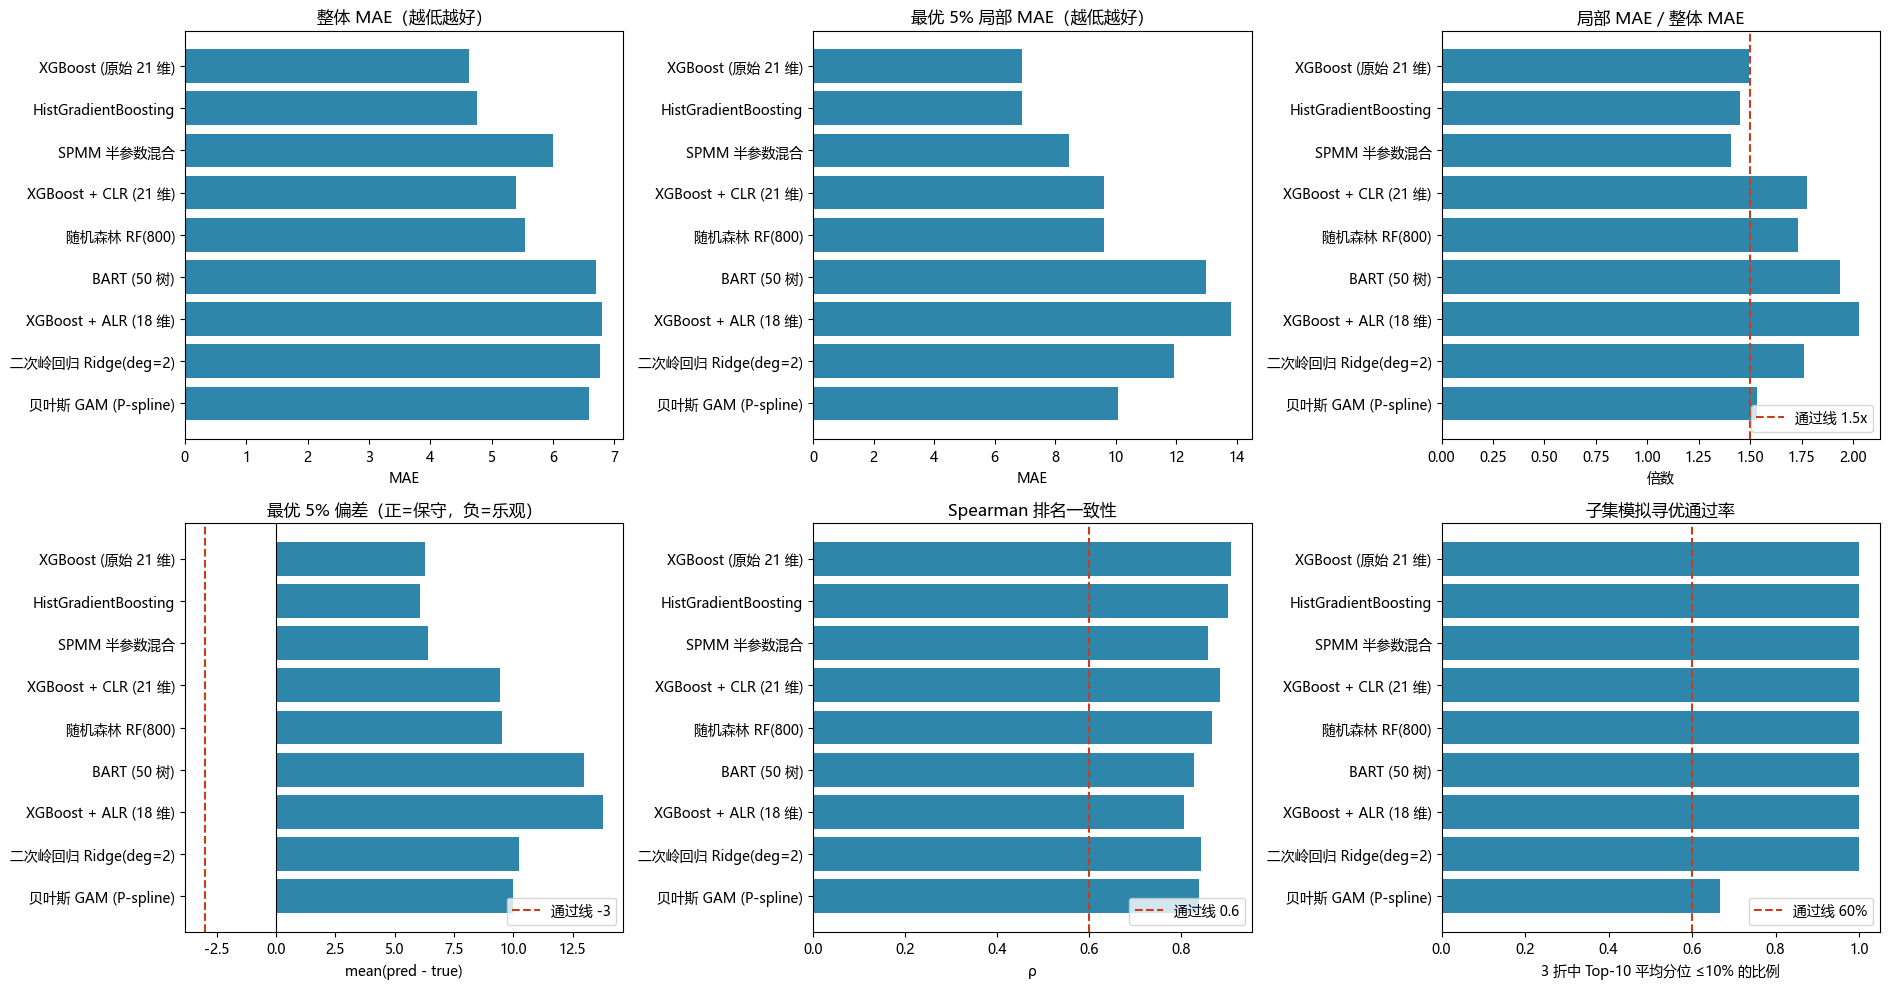

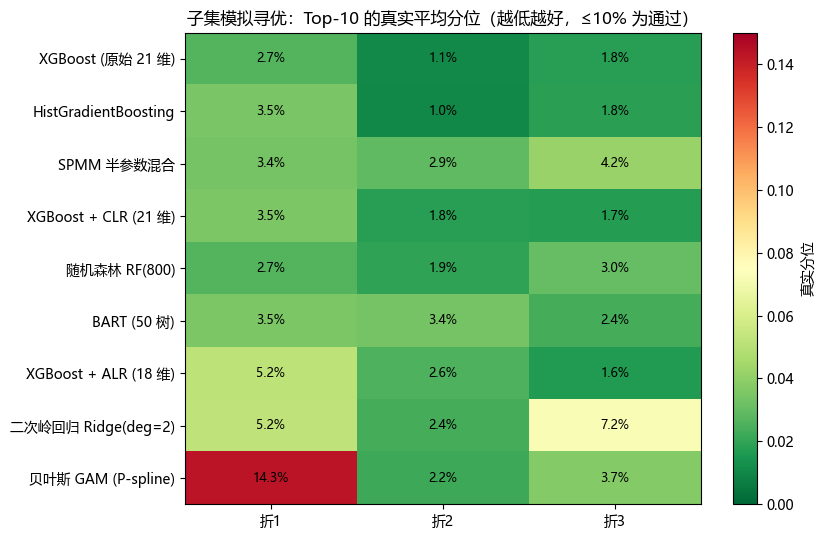

In [9]:
# ---------- 图 1：六项核心指标 ----------
plot_df = metrics_df.copy()
labels = plot_df["模型"].tolist()
colors = ["#2E86AB" if c >= 3 else "#C73E1D" for c in plot_df["通过检查数"]]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

ax = axes[0, 0]
ax.barh(labels, plot_df["整体MAE"], color=colors)
ax.invert_yaxis()
ax.set_title("整体 MAE（越低越好）")
ax.set_xlabel("MAE")

ax = axes[0, 1]
ax.barh(labels, plot_df["最优5% MAE"], color=colors)
ax.invert_yaxis()
ax.set_title("最优 5% 局部 MAE（越低越好）")
ax.set_xlabel("MAE")

ax = axes[0, 2]
ratio = plot_df["局部/整体"]
ax.barh(labels, ratio, color=colors)
ax.axvline(1.5, color="#C73E1D", ls="--", lw=1.5, label="通过线 1.5x")
ax.invert_yaxis()
ax.set_title("局部 MAE / 整体 MAE")
ax.set_xlabel("倍数")
ax.legend(loc="lower right")

ax = axes[1, 0]
ax.barh(labels, plot_df["偏差"], color=colors)
ax.axvline(-3, color="#C73E1D", ls="--", lw=1.5, label="通过线 -3")
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_title("最优 5% 偏差（正=保守，负=乐观）")
ax.set_xlabel("mean(pred - true)")
ax.legend(loc="lower right")

ax = axes[1, 1]
ax.barh(labels, plot_df["Spearman ρ"], color=colors)
ax.axvline(0.6, color="#C73E1D", ls="--", lw=1.5, label="通过线 0.6")
ax.invert_yaxis()
ax.set_title("Spearman 排名一致性")
ax.set_xlabel("ρ")
ax.legend(loc="lower right")

ax = axes[1, 2]
ax.barh(labels, plot_df["子集通过率"], color=colors)
ax.axvline(0.6, color="#C73E1D", ls="--", lw=1.5, label="通过线 60%")
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_title("子集模拟寻优通过率")
ax.set_xlabel("3 折中 Top-10 平均分位 ≤10% 的比例")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# ---------- 图 2：子集寻优逐折真实分位热力图 ----------
model_order = metrics_df["模型"].tolist()
mat = np.array([[r.mean_true_percentile for r in results[n]["report"].subset_runs] for n in model_order])
fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(mat, cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=max(0.15, float(mat.max())))
ax.set_xticks(range(mat.shape[1]))
ax.set_xticklabels([f"折{i+1}" for i in range(mat.shape[1])])
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i, j]*100:.1f}%", ha="center", va="center",
                fontsize=9, color="black")
ax.set_title("子集模拟寻优：Top-10 的真实平均分位（越低越好，≤10% 为通过）")
fig.colorbar(im, ax=ax, label="真实分位")
plt.tight_layout()
plt.show()

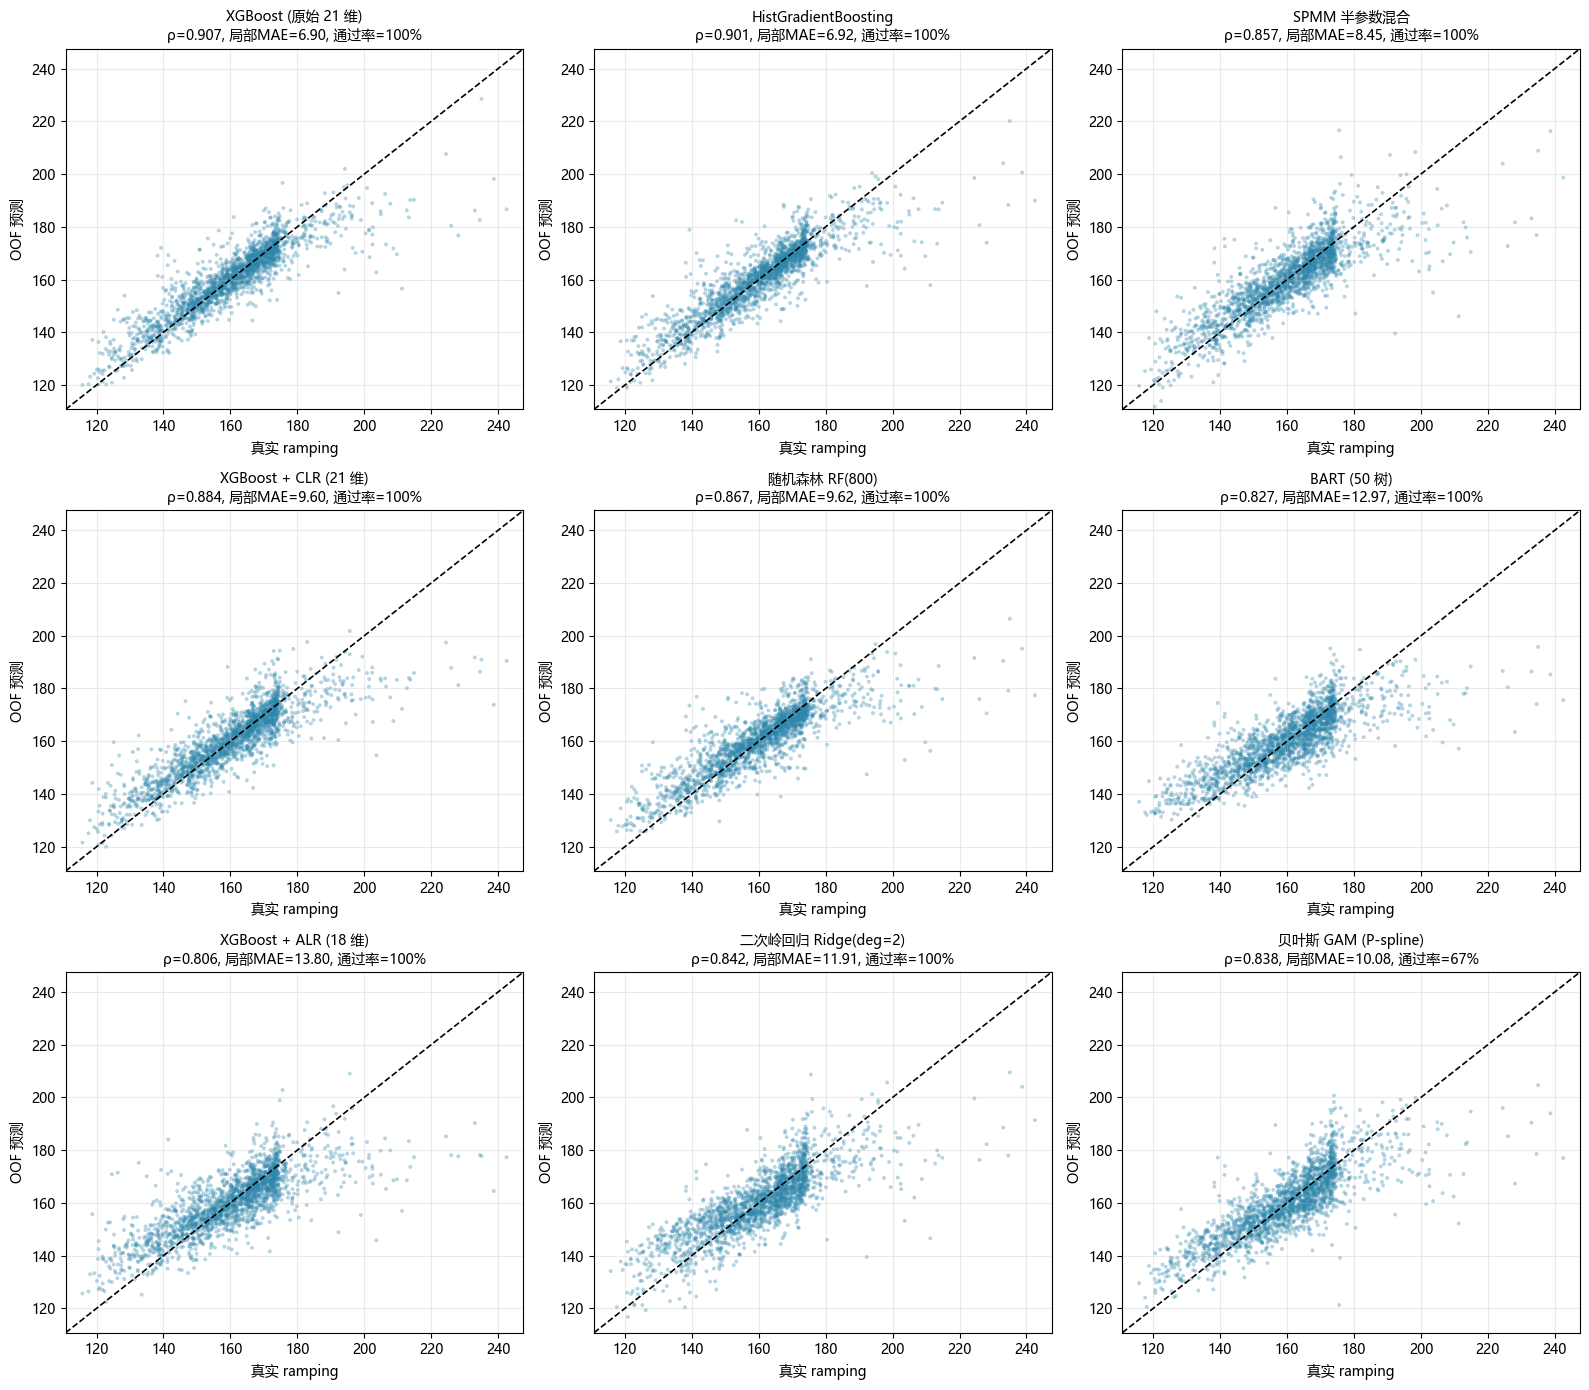

In [10]:
# ---------- 图 3：9 个模型的 OOF 预测 vs 真实值 ----------
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
lims = [y.min() - 5, y.max() + 5]
for ax, name in zip(axes.ravel(), metrics_df["模型"]):
    r = results[name]
    oof = r["oof"]
    rep = r["report"]
    ax.scatter(y, oof, s=8, alpha=0.35, color="#2E86AB", edgecolors="none")
    ax.plot(lims, lims, "k--", lw=1.2)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(f"{name}\nρ={rep.ranking.spearman_r:.3f}, "
                 f"局部MAE={rep.local.mae:.2f}, 通过率={rep.subset_pass_rate:.0%}",
                 fontsize=10)
    ax.set_xlabel("真实 ramping")
    ax.set_ylabel("OOF 预测")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Top-3 代理模型

按第 4.2 节的排序规则（通过检查数 → 子集通过率 → Top-K 平均真实分位 → 最优 5% MAE），取前 3 名。


In [11]:
top3 = metrics_df.head(3)
display(top3[["模型", "通过检查数", "子集通过率", "平均Top-K分位",
              "最优5% MAE", "整体MAE", "偏差", "Spearman ρ", "判定"]].style.format({
    "通过检查数": "{}/4", "子集通过率": "{:.0%}", "平均Top-K分位": "{:.1%}",
    "最优5% MAE": "{:.2f}", "整体MAE": "{:.2f}", "偏差": "{:+.2f}", "Spearman ρ": "{:.3f}",
}))

for rank, (_, row) in enumerate(top3.iterrows(), 1):
    print(f"Top-{rank}: {row['模型']} —— {row['判定']}")
    print(f"        整体MAE={row['整体MAE']:.2f}, 最优5%MAE={row['最优5% MAE']:.2f}, "
          f"偏差={row['偏差']:+.2f}, ρ={row['Spearman ρ']:.3f}, "
          f"子集通过率={row['子集通过率']:.0%}, 平均Top-K分位={row['平均Top-K分位']:.1%}")

,模型,通过检查数,子集通过率,平均Top-K分位,最优5% MAE,整体MAE,偏差,Spearman ρ,判定
0,XGBoost (原始 21 维),4/4,100%,1.8%,6.90,4.63,+6.28,0.907,✅ 推荐使用：模型在寻优场景下可靠
1,HistGradientBoosting,4/4,100%,2.1%,6.92,4.76,+6.06,0.901,✅ 推荐使用：模型在寻优场景下可靠
2,SPMM 半参数混合,4/4,100%,3.5%,8.45,6.00,+6.38,0.857,✅ 推荐使用：模型在寻优场景下可靠


Top-1: XGBoost (原始 21 维) —— ✅ 推荐使用：模型在寻优场景下可靠
        整体MAE=4.63, 最优5%MAE=6.90, 偏差=+6.28, ρ=0.907, 子集通过率=100%, 平均Top-K分位=1.8%
Top-2: HistGradientBoosting —— ✅ 推荐使用：模型在寻优场景下可靠
        整体MAE=4.76, 最优5%MAE=6.92, 偏差=+6.06, ρ=0.901, 子集通过率=100%, 平均Top-K分位=2.1%
Top-3: SPMM 半参数混合 —— ✅ 推荐使用：模型在寻优场景下可靠
        整体MAE=6.00, 最优5%MAE=8.45, 偏差=+6.38, ρ=0.857, 子集通过率=100%, 平均Top-K分位=3.5%


<!-- TOP3_ANALYSIS -->
### 6.1 第 1 名：XGBoost（原始 21 维）—— 主代理模型（与 HistGB 同处第一梯队）

**一句话结论**：整体 MAE、Spearman ρ、Top-K 平均真实分位三项排第 1；最优 5% MAE 与 HistGB 基本持平（6.90 vs 6.92，差 0.2%），局部 RMSE/R² 反而 HistGB 略好。可以作为首选主代理，但“第一”只是点估计，差距并不显著。

| 关键指标 | 数值 | 说明 |
|---|---|---|
| 整体 MAE / OOF R² | **4.63 / 0.793** | 9 个模型中最低误差 / 最高解释度 |
| 最优 5% MAE | **6.90** | 最低，但与 HistGB 的 6.92 仅差 0.2%，在噪声范围内；局部/整体 = **1.49×**，离 1.5× 通过线仅剩 0.01 |
| 最优 5% 偏差 | **+6.28** | 偏保守（把好解说差），未低估好解 |
| Spearman ρ | **0.907** | 最高（HistGB 0.901），排序最可靠 |
| 子集寻优 | **3/3 通过**，平均分位 **1.83%** | 3 折都选中了 holdout 真实最优（排名 0/683、0/683、0/682，gap=0） |
| 整轮评估耗时 | **18.5 s** | 含 5 折 OOF + 全量重训 + 3 折子集寻优；线程配置未与 HistGB 统一，见 6.2 |

**优势**

1. **整体精度与排序第 1，尾部与 HistGB 基本持平**：整体 MAE 比 HistGB 低 2.9%，比 SPMM 低 23%；ρ 最高（0.907 vs 0.901）。但局部 MAE、局部 RMSE、局部 R² 与 HistGB 的差异都在 0.2% 量级，不足以区分两者。
2. **尾部（最优 5%）误差最小，但与第 2 名几乎相同**：局部 MAE 6.90 vs HistGB 6.92（差 0.2%）；局部 RMSE 8.88 vs 8.87、局部 R² -3.56 vs -3.56，HistGB 略优。偏差 +6.28，与 HistGB（+6.06）同一量级。因此不应表述为“唯一明显领先”。
3. **子集寻优零 gap**：3 折 Top-10 都命中了真实最优，说明它预测出的低 ramping 区域与真实最优区域高度重合，而不是“碰巧”排对。
4. **工程成本可控**：18.5 s 完成整轮评估，快于 BART（271.8 s）和 GAM（167.9 s）。但这是单次测量、线程未统一的数字，只能作参考。
5. **对原始权重空间友好**：不需要成分数据变换，21 维原始权重即可获得最佳效果，解释与落库成本最低。

**劣势与风险**

1. **局部精度是“压线通过”**：1.49× 距 1.5× 通过线只有 0.01，换折分或换随机种子就可能掉到 ⚠️；结论需要在独立 holdout 上复核。
2. **与 HistGB 的差距小于噪声**：局部 MAE 差 0.2%、整体 MAE 差 2.9%，而本报告只有单次折分、没有置信区间与配对检验（见 7.4），不能据此宣称 XGB 显著优于 HistGB。
3. **尾部 R² 为负（-3.56）**：最优 5% 区域真实值只在 115.8–132.8 之间，方差很小；预测整体向均值收缩并叠加 +6.28 的正偏差，使局部 R² 天然失真。这不代表模型整体不可用（整体 R²=0.793），但说明**不能用它预测尾部的绝对 ramping 水平**。
4. **树模型是分段常数，不能外推**：若寻优把权重推到训练支撑域之外（极端稀疏权重），预测会停在最近的叶子值，可能误导搜索。
5. **无原生不确定性**：无法给出“这个解到底有多好”的置信区间，只能给点预测。
6. **超参敏感**：depth / lr / n_estimators 对结果影响明显，必须固定搜索协议与随机种子。

**适用场景**：作为主代理做全局筛选 + 局部精搜（HistGB 可近似等价替换）；或作为三模型集成中的核心成员。**不建议**直接用它的单点预测作为最终决策，必须配合真实评估复核。

### 6.2 第 2 名：HistGradientBoosting —— XGB 的平行替身

| 关键指标 | 数值 | 说明 |
|---|---|---|
| 整体 MAE / OOF R² | 4.76 / 0.784 | 仅比 XGB 差 2.9% |
| 最优 5% MAE | 6.92 | 与 XGB 几乎持平；局部/整体 = **1.45×**，余量更大 |
| 最优 5% 偏差 | **+6.06** | 三甲中最小，尾部最不“过度保守” |
| Spearman ρ | 0.901 | 第 2 |
| 子集寻优 | **3/3 通过**，平均分位 **2.10%** | 2 折命中真实最优；折 3 选中第 2 名（1/682，gap=+0.8） |
| 整轮评估耗时 | 43.8 s | 单次测量，线程配置与 XGB 不统一，不可严格横比 |

**优势**

1. **与 XGB 几乎相同的精度**：整体、局部、排序、子集四项均只差 1%–15%，是可以“无缝替换”的第二模型；局部 RMSE（8.87 vs 8.88）与局部 R²（-3.557 vs -3.565）甚至略优于 XGB。
2. **局部/整体 1.45×，通过余量比 XGB 更大**：在折分扰动下更稳，不容易掉出 4/4。
3. **偏差最小（+6.06）**：在最优区域最接近真实值，保守程度最低。
4. **工程友好**：直方图分箱内存小、原生支持缺失值、超参更少（主要是 depth / lr / max_iter），适合批量跑多种子或大候选池。
5. **稳定性好**：没有 XGB 的 subsample/colsample 随机性，重复训练结果更一致。

**劣势**

1. **整体误差与排序第 2，局部 RMSE/R² 与 XGB 互有胜负**：没有单项明显领先，属于“稳但不尖”的模型。
2. **折 3 未命中真实最优**：Top-10 最优真实值 120.1 vs 真实最优 119.3（gap +0.8），说明在候选池边缘会漏掉极值。
3. **分箱损失尾部分辨率**：ramping 最优区域对应的权重可能非常接近 0，直方图分箱会把这些细微差异合并，限制极端区域的排序能力。
4. **无不确定性、不能外推**：与 XGB 相同；且对单调约束、交互约束的支持不如 XGB 灵活。
5. **耗时不可与 XGB 严格横比**：HistGB 的 `n_threads=None` 会使用 OpenMP 默认线程数（通常是全部可用核），XGB 显式设置 `n_jobs=-1`，两者线程配置并不统一；且都是单次测量、未计预热与内存开销。43.8 s vs 18.5 s 只代表本机、本配置下的参考值，不能据此推断算法本身更慢。

**适用场景**：XGB 的平行替身/快速基线；多种子集成中的第二成员；对内存和部署简洁性要求高的场景。

### 6.3 第 3 名：SPMM 半参数混合 —— 平滑响应面与集成补充

| 关键指标 | 数值 | 说明 |
|---|---|---|
| 整体 MAE / OOF R² | 6.00 / 0.694 | 仅排第 5，明显落后于树模型 |
| 最优 5% MAE | 8.45 | 第 3；局部/整体 = **1.41×**，**9 个模型中余量最大** |
| 最优 5% 偏差 | +6.38 | 与 XGB/HistGB 同一量级 |
| Spearman ρ | 0.857 | 第 5 |
| 子集寻优 | **3/3 通过**，平均分位 **3.48%** | 2 折命中真实最优；折 3 第 2 名（1/682，gap=+0.8） |
| 整轮评估耗时 | **1.3 s** | 三甲中最快（单次测量，线程未统一） |

**优势**

1. **局部/整体 1.41×，通过余量最大**：虽然绝对误差不如 XGB，但“尾部相对整体”的退化最小，说明它在最优区域没有明显崩坏。
2. **响应面平滑可微**：二次趋势 + RBF 残差修正，预测函数连续，不像树模型那样分段常数；若后续要做梯度类/局部搜索，SPMM 的梯度信息更可靠。
3. **训练成本极低**：整轮评估 1.3 s，可做大量 bootstrap、多种子、滚动重训，适合做集成底座。
4. **误差结构与树模型不同**：它的错误主要来自核平滑，而 XGB/HistGB 来自分段常数；三者做秩平均能有效对冲尾部偏差。
5. **在 1.5× 门槛下 4/4 通过**：它比全局 MAE 更好的 RF（5.55）和 CLR（5.40）更“合格”，原因是后两者的局部/整体比为 1.73×/1.78×，卡在 1.5× 之外；若门槛升到 1.78×，RF/CLR 同样 4/4 通过，且 CLR 的 Top-K 平均分位（2.35%）优于 SPMM（3.48%），排序上会超过 SPMM（见 6.5）。因此“SPMM 是第 3 名”是门槛依赖的结论。

**劣势**

1. **全局精度明显落后**：整体 MAE 6.00，比 XGB 差 30%，OOF R² 仅 0.694；作为唯一主模型会浪费候选池质量。
2. **尾部绝对误差大**：最优 5% RMSE 10.58、R² -5.47，Top-K 平均真实分位 3.48%（三甲中最高），挑极值能力弱于 XGB/HistGB。
3. **核方法成本 O(n²)**：样本量从 2048 增加一个量级时，核矩阵会先成为瓶颈；当前 1.3 s 的优势不可线性外推。
4. **超参更敏感**：`alpha_linear / alpha_kernel / gamma` 三者耦合，换数据分布需重新搜索；RBF 核在训练支撑域外会快速衰减，外推同样不可靠。
5. **结构假设较强**：二次项 + 单核残差，对 21 维成分约束的表达是隐式的，复杂交互可能欠拟合。

**适用场景**：第二/第三模型做秩平均集成；需要平滑响应面或梯度信息的局部搜索；样本量不大、需要快速反复重训的场景。

### 6.4 落选模型的主要原因

| 模型 | 通过检查 | 关键短板 | 结论 |
|---|---|---|---|
| XGBoost + CLR | 3/4 | 局部 MAE 9.60 > 1.5×5.40=8.10；偏差 +9.45 | 全局第 3、子集 3/3 全中，但尾部精度不达标；CLR 变换没有带来增益 |
| 随机森林 RF(800) | 3/4 | 局部 MAE 9.62 > 1.5×5.55=8.33；偏差 +9.51 | 全局 MAE 优于 SPMM，但 bagging 平均加剧向均值收缩，挑极值不如树提升 |
| BART (50 树) | 3/4 | 局部 MAE 12.97、偏差 +12.97 | 收缩最严重；优势在后验区间而非点预测，适合不确定性评估，不适合挑极值 |
| XGBoost + ALR | 3/4 | 局部 MAE 13.80、偏差 +13.79、局部/整体 2.03× | 全面最差，ALR 对树模型明确有害 |
| 二次岭回归 Ridge | 3/4 | 局部 MAE 11.91、偏差 +10.21 | 全局平滑但尾部系统性高估；适合做基线/解释，不适合单独寻优 |
| 贝叶斯 GAM | 3/4 | 局部 MAE 10.08 > 1.5×6.58=9.88；折 1 分位 14.3% | 可解释性最好，但尾部精度和子集稳定性不足（通过率 2/3） |

> **关键判读**：9 个模型的偏差全部为正（+6.06 ~ +13.79），没有任何模型“低估好解”，所以评估器的偏差项全部通过。真正的分水岭是**局部 MAE 是否 ≤ 1.5× 整体 MAE**——在默认门槛下它筛掉了 RF、CLR、BART、GAM、Ridge、ALR。但这条线是启发式门槛：把门槛移到 1.78×，RF、CLR、Ridge 也会通过（见 6.5）。另一个容易误读的点是**局部 R² 全为负**：最优 5% 区域真实值方差很小，任何向均值收缩都会让 R² 变成大负数；评估器因此用局部 MAE 和偏差方向而不是 R² 作为判据。

### 6.5 门槛敏感性：Top-3 有多稳？

评估器的 1.5× 是启发式门槛，不是数据生成机制决定的常数。下表**只依据第 4.2 节已有的“局部/整体”比率重算**（不重跑任何模型），观察门槛移动时谁通过、Top-3 如何变化：

| 局部 MAE 门槛 | 4/4 通过的模型 | Top-3（按同一排序规则） |
|---|---|---|
| 1.40× | 无 | XGB、HistGB、CLR |
| 1.45× | SPMM | SPMM、XGB、HistGB |
| 1.50×（评估器默认） | XGB、HistGB、SPMM | XGB、HistGB、SPMM |
| 1.55× | XGB、HistGB、SPMM、GAM | XGB、HistGB、SPMM |
| 1.60× | XGB、HistGB、SPMM、GAM | XGB、HistGB、SPMM |
| 1.75× | XGB、HistGB、SPMM、GAM、RF | XGB、HistGB、RF |
| 1.78× | XGB、HistGB、SPMM、GAM、RF、CLR、Ridge | XGB、HistGB、CLR |

**怎么读**：

- **前两名稳定**：XGB 与 HistGB 在 1.40×–1.78× 的全部区间内都进 Top-2，顺序也不随门槛变化。它们的差距（局部 MAE 0.2%）本来就小于选择噪声，因此“谁第一”不应被强调。
- **第三名不稳定**：门槛 ≤1.45× 时是 CLR 或 SPMM，1.50×–1.60× 为 SPMM，≥1.75× 换成 RF，1.78× 又换成 CLR。也就是说，“SPMM 是第 3 名”是 1.5× 这个特定门槛的产物，不是稳健结论。
- **门槛越低，排序越接近“纯精度排序”**：1.40× 时没有任何模型 4/4 通过，排序退化为按子集分位/局部 MAE 排，Top-3 变为 XGB、HistGB、CLR。
- **建议的表述**：XGB 与 HistGB 组成第一梯队；第三名在 SPMM / RF / CLR 之间随门槛与折分摆动，不宜写死。


<!-- CONCLUSION -->
## 7. 总体结论与落地建议

### 7.1 五条结论

1. **代理模型整体可用，但“能排序”不等于“能精确预测尾部”**。9 个模型 Spearman ρ 全部 ≥ 0.806、子集通过率全部 ≥ 67%，说明 ramping 与 21 维权重之间存在可学习的强结构；但所有模型在最优 5% 区域都保守（偏差 +6.06 ~ +13.79），局部 R² 全为负。
2. **在评估器默认的 1.5× 门槛下，只有 XGBoost(RAW)、HistGradientBoosting、SPMM 通过全部 4 项检查**。三者的共同点是局部 MAE 控制在整体 MAE 的 1.41–1.49 倍，且子集寻优 3/3 通过；其余模型都倒在“局部 MAE ≤ 1.5× 整体”这条线上。但这是一条离散的启发式门槛，门槛移到 1.75×/1.78× 时 RF、CLR 也会通过（见 6.5），第三名并不稳健。
3. **特征表示：原始 21 维 > CLR > ALR**。CLR 的全局 MAE 5.40 尚可，但尾部 MAE 9.60、偏差 +9.45；ALR 全面最差（整体 6.80、局部 13.80、偏差 +13.79、局部/整体 2.03×）。对树模型而言，对成分数据做对数比变换后再分裂没有收益，反而破坏了极低权重区的分辨率。
4. **模型复杂度不等于尾部精度**。BART（MCMC + 50 树）和 RF（800 树 bagging）的尾部偏差（+12.97 / +9.51）反而大于更简单的 XGB/HistGB；平均/后验收缩会系统性地把好解预测得偏差。贝叶斯模型的价值在区间估计，不在挑极值。
5. **成本差异明显，但只能在给定实现/线程配置/单次测量下比较**：整轮评估（5 折 OOF + 全量重训 + 3 折子集寻优）耗时 SPMM 1.3 s、XGB 18.5 s、RF 38.1 s、HistGB 43.8 s、GAM 167.9 s、BART 271.8 s。XGB 的精度/成本组合最好；由于 HistGB 使用 OpenMP 默认线程数、XGB 显式 `n_jobs=-1`，且均未做重复计时，这些数字不能作为严格的效率排名。

### 7.2 推荐工作流

1. **主模型**：XGBoost（原始 21 维）做大规模候选筛选，取预测最低的 Top-20~Top-50；HistGradientBoosting 可近似等价替换（两者差距在噪声内）。
2. **集成复核**：用 HistGradientBoosting 与 SPMM 分别预测同一候选池，对三者排名做秩平均（Borda），取集成 Top-10~Top-20。三种误差结构互补，可降低单模型尾部偏差。
3. **真实评估闭环**：把集成 Top-K 交给模拟器/真实评估，选真实 ramping 最低者；不要直接用代理模型的预测值作为最终成绩。
4. **需要不确定性时**：用 BART 的后验区间做风险筛查（例如剔除预测区间上界过高的解），但不使用其点预测挑极值。
5. **需要可解释性时**：用 GAM 的单变量光滑曲线或 Ridge 的二次系数做机理说明，仅用于粗筛与汇报。

### 7.3 选型速查

| 需求 | 首选 | 备选 | 不建议 |
|---|---|---|---|
| 最高寻优精度（主模型） | XGBoost (RAW) / HistGB（基本持平） | SPMM（第三名，门槛依赖） | ALR、Ridge、BART |
| 快速批量重训 | SPMM (1.3 s) | XGBoost (18.5 s) | BART、GAM |
| 平滑响应面/梯度信息 | SPMM | — | 树模型（分段常数） |
| 不确定性量化 | BART | — | 点预测模型 |
| 可解释性 | GAM / Ridge | — | 黑箱集成 |
| 集成多样性 | XGB + HistGB + SPMM | + RF | ALR |

### 7.4 风险与复核建议

- **选择–评估循环**：超参数先在**全量 2048 条**上用 `KFold(5, seed=2026)` 选出，再用**同一折分**做 OOF。模型选择与评估共用同一批验证折，属于 selection–evaluation loop：OOF 指标是乐观估计，**误差应视为下界、性能应视为上界**。要消除它需用嵌套 CV（内层选参、外层评估）或独立 holdout。9 个模型处理一致，**排序方向大体可信，但绝对数值以及 XGB/HistGB 之间的微小差距不可信**。
- **无重复 CV、无置信区间、无配对检验**：全表来自单次折分（seed=2026），没有重复 CV、均值±标准差，也没有模型间的配对显著性检验。XGB 与 HistGB 的局部 MAE 差 0.2%、整体 MAE 差 2.9%，均小于此类噪声量级，报告不应据此宣称“XGB 明显领先”。
- **XGBoost 是压线通过**：局部/整体 = 1.49×，距 1.5× 只有 0.01。换折分、换种子或换数据批次都可能让它变成 ⚠️。建议在独立 holdout 上复测 3–5 次折分，报告均值与区间。
- **局部样本量小**：最优 5% 只有 103 条（阈值 132.80），局部 MAE/R² 波动不可忽略；应结合每折约 683 条的子集寻优结果一起判断。
- **调参预算不一致**：XGB/HistGB/SPMM/Ridge 在本协议内做了网格搜索；BART/GAM 沿用仓库配置，RF 仅在另一划分（7:1.5:1.5）上比较过 8 组配置。未获同等预算的模型处于结构性劣势，建议补做同等预算的调参后再比较（见第 2 节）。
- **子集寻优的边界**：它只验证“在 holdout 候选池中挑 Top-10”的能力，不等价于连续空间优化；真实寻优仍需模拟器闭环。
- **MCMC 模型可复现性**：GAM/BART 固定种子可复现，但链长、thin、种子变化会带来小幅波动；报告中的数值对应本 notebook 的固定配置。
- **分布外风险**：所有模型（包括 SPMM 的 RBF 核）在训练支撑域外都不可靠；寻优时应给权重加上下界/稀疏度约束，避免搜索到无样本覆盖的极端区域。


## 附录：复现说明与局限

- 运行环境：Python 3.11，scikit-learn 1.6.1，xgboost 3.4.1，bartpy2 0.0.2。
- 统一折分：`KFold(5, shuffle=True, random_state=2026)` 用于 OOF；评估器内部 `KFold(3, shuffle=True, random_state=2026)` 用于子集寻优。
- 超参数均在**全量数据**上通过 `KFold(5, seed=2026)` 选择，随后用**同一折分**做 OOF 预测，构成 selection–evaluation loop：OOF 误差是乐观估计，应视为下界，不能当作泛化性能；9 个模型处理一致，排序方向可参考。
- 仅做了**单次折分**，未做重复 CV，也未报告置信区间或模型间配对检验；表中小于约 3% 的差异不应解读为显著。
- 调参预算不一致：XGB/HistGB/SPMM/Ridge 在本协议内调参，BART/GAM 沿用外部配置，RF 仅在 7:1.5:1.5 划分上比较过 8 组配置，详见第 2 节。
- 耗时为单次测量，且线程配置不同（XGB/RF 显式 `n_jobs=-1`，HistGB 使用 OpenMP 默认线程数），不可严格横比。
- BART 和 GAM 为 MCMC 后验模型，单次拟合存在采样噪声；本报告用固定种子（`SEED=2026`）保证可复现。
- 最优 5% 区域只有 103 条样本（阈值 132.80），局部 MAE/R² 仍有统计波动；子集寻优每折 holdout 约 683 条，Top-10 的真实排名同样带有抽样随机性。
- 评估器只衡量“在已有候选池中挑好解”的能力，不等价于真实环境中的控制器收益；最终仍需以真实评估/模拟器验证为准。
